#00. Import Library

In [ ]:
import os
import zipfile

import cv2
import numpy as np
import matplotlib.pyplot as plt

#01. Image preparation

rice (256, 256) | A (512, 512) | B (512, 512) | parrot (1018, 1524)


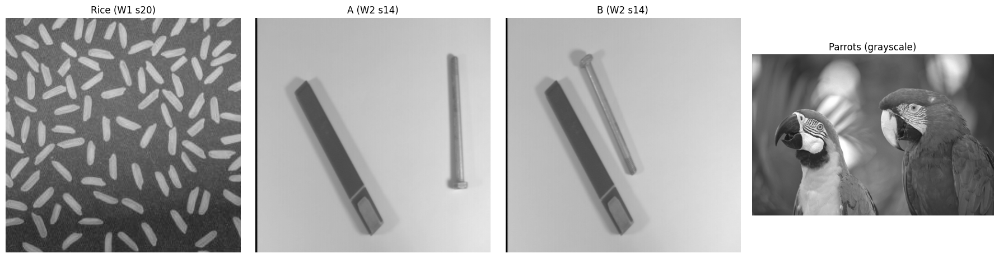

In [ ]:
BASE = 'images'

if not os.path.isdir(BASE):
    zipfile.ZipFile('images.zip').extractall()

# binarization : Week1_2 slide20 (Original gray-scale image)
rice     = cv2.imread(f'{BASE}/03_binarization/rice_gray.png', cv2.IMREAD_GRAYSCALE)
rice_ref = cv2.imread(f'{BASE}/03_binarization/rice_binary_ref.png', cv2.IMREAD_GRAYSCALE)

# logical method : Week_2-2 slide14, 16 (A, B)
A = cv2.imread(f'{BASE}/01_arithmetic/A_bolt.png', cv2.IMREAD_GRAYSCALE)
B = cv2.imread(f'{BASE}/01_arithmetic/B_bolt.png', cv2.IMREAD_GRAYSCALE)

# morphology : dilation grayscale image
PARROT_PATH = f'{BASE}/02_morphology/parrots_gray.png'
parrot = cv2.imread(PARROT_PATH, cv2.IMREAD_GRAYSCALE)
assert parrot is not None, f'이미지를 찾을 수 없음 : {PARROT_PATH}'

print('rice', rice.shape, '| A', A.shape, '| B', B.shape, '| parrot', parrot.shape)


def show(images, titles, cols=3):
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=(4.5 * cols, 4.5 * rows))
    for i, (im, t) in enumerate(zip(images, titles), 1):
        plt.subplot(rows, cols, i)
        plt.imshow(im, cmap='gray', vmin=0, vmax=255)
        plt.title(t); plt.axis('off')
    plt.tight_layout(); plt.show()


show([rice, A, B, parrot], ['Rice (W1 s20)', 'A (W2 s14)', 'B (W2 s14)', 'Parrots (grayscale)'], cols=4)

#02_1. Global Thresholding

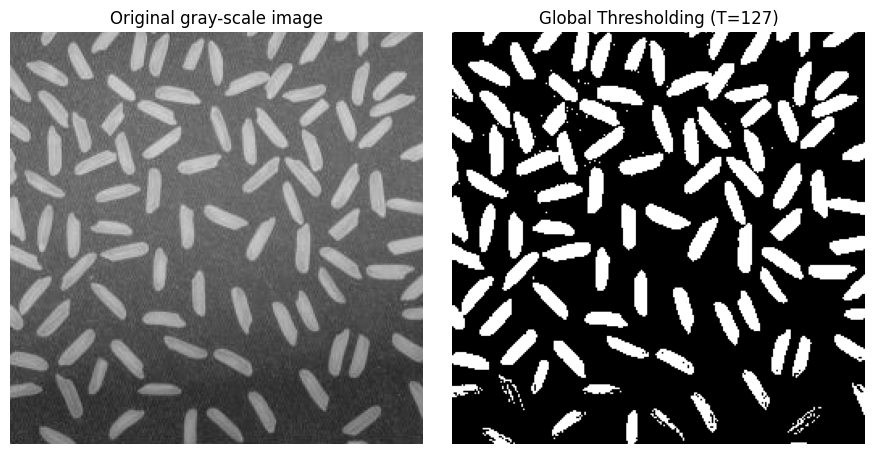

In [ ]:
_, th_global = cv2.threshold(rice, 127, 255, cv2.THRESH_BINARY)

show([rice, th_global], ['Original gray-scale image', 'Global Thresholding (T=127)'], cols=2)

#02_2. Adaptive Thresholding

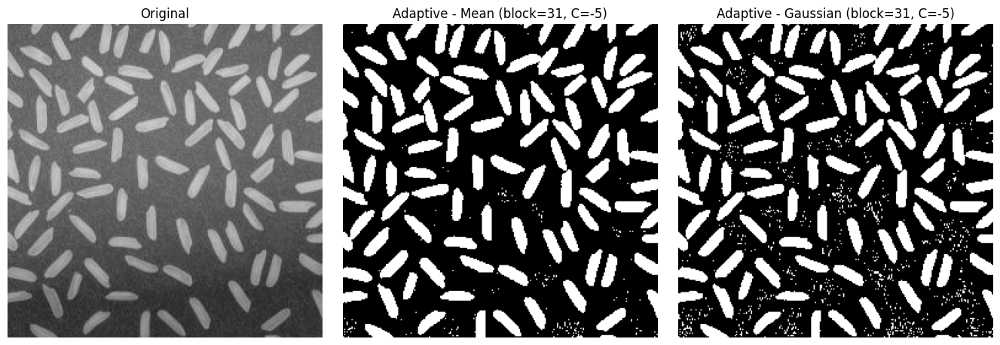

In [ ]:
th_mean  = cv2.adaptiveThreshold(rice, 255, cv2.ADAPTIVE_THRESH_MEAN_C,     cv2.THRESH_BINARY, 31, -5)
th_gauss = cv2.adaptiveThreshold(rice, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, -5)

show([rice, th_mean, th_gauss],
     ['Original', 'Adaptive - Mean (block=31, C=-5)', 'Adaptive - Gaussian (block=31, C=-5)'], cols=3)

#02_3. Otsu's Thresholding

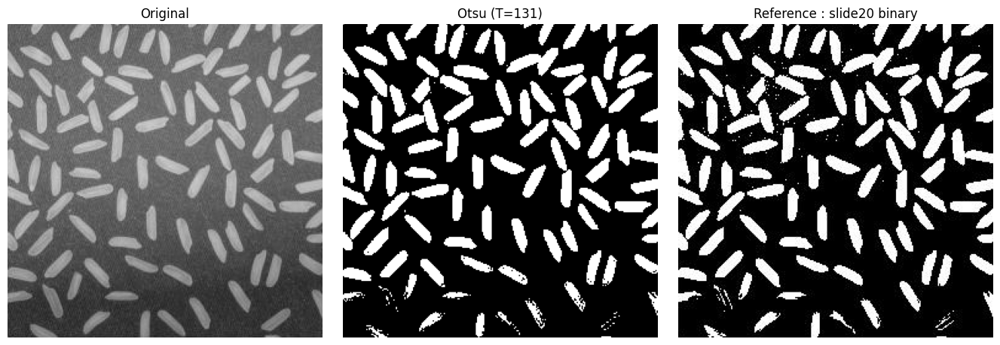

In [ ]:
t_otsu, th_otsu = cv2.threshold(rice, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show([rice, th_otsu, rice_ref],
     ['Original', f'Otsu (T={t_otsu:.0f})', 'Reference : slide20 binary'], cols=3)

#02_4. Minimum Error Thresholding

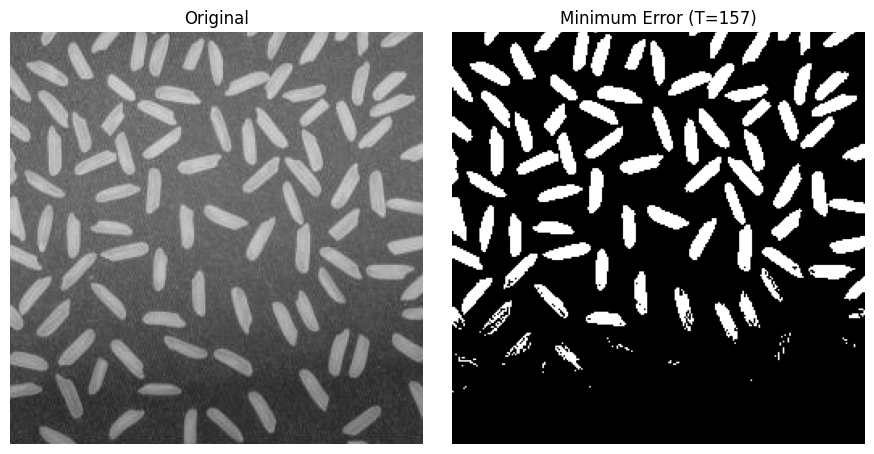

In [ ]:
def minimum_error_threshold(image):   # Kittler-Illingworth
    p = cv2.calcHist([image], [0], None, [256], [0, 256]).ravel()
    p, lv, eps = p / p.sum(), np.arange(256), 1e-12

    w0, w1 = np.cumsum(p), 1.0 - np.cumsum(p)                                       # prob of two classes
    c1, c2 = np.cumsum(p * lv), np.cumsum(p * lv ** 2)
    m0, m1 = c1 / np.maximum(w0, eps), (c1[-1] - c1) / np.maximum(w1, eps)          # average
    s0 = np.sqrt(np.maximum(c2 / np.maximum(w0, eps) - m0 ** 2, eps))               # std
    s1 = np.sqrt(np.maximum((c2[-1] - c2) / np.maximum(w1, eps) - m1 ** 2, eps))

    J = (1 + 2 * (w0 * np.log(s0) + w1 * np.log(s1))
           - 2 * (w0 * np.log(np.maximum(w0, eps)) + w1 * np.log(np.maximum(w1, eps))))
    J[(w0 < 1e-6) | (w1 < 1e-6)] = np.inf
    return int(np.argmin(J))                                                        # threshold


t_min_err = minimum_error_threshold(rice)
_, th_min_err = cv2.threshold(rice, t_min_err, 255, cv2.THRESH_BINARY)

show([rice, th_min_err], ['Original', f'Minimum Error (T={t_min_err})'], cols=2)

#02_5. Binarization results

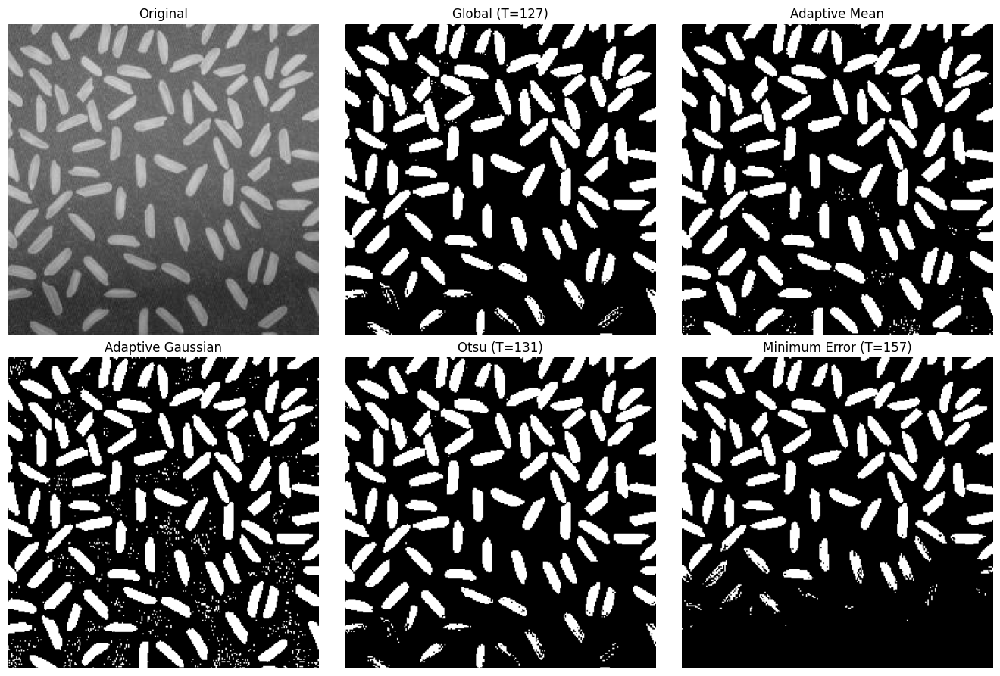

Method            Threshold   Foreground(%)  
---------------------------------------------
Global            127         26.97          
Otsu              131         25.94          
Minimum Error     157         19.38          


In [ ]:
show([rice, th_global, th_mean, th_gauss, th_otsu, th_min_err],
     ['Original', 'Global (T=127)', 'Adaptive Mean', 'Adaptive Gaussian',
      f"Otsu (T={t_otsu:.0f})", f'Minimum Error (T={t_min_err})'], cols=3)

print(f'{"Method":<18}{"Threshold":<12}{"Foreground(%)":<15}')
print('-' * 45)
for name, t, im in [('Global', 127, th_global), ('Otsu', int(t_otsu), th_otsu),
                    ('Minimum Error', t_min_err, th_min_err)]:
    print(f'{name:<18}{t:<12}{100 * np.count_nonzero(im) / im.size:<15.2f}')

#03_1. Addition

A + B =
 [[ 10 200  15]
 [  6   0  10]
 [  8  10  15]]


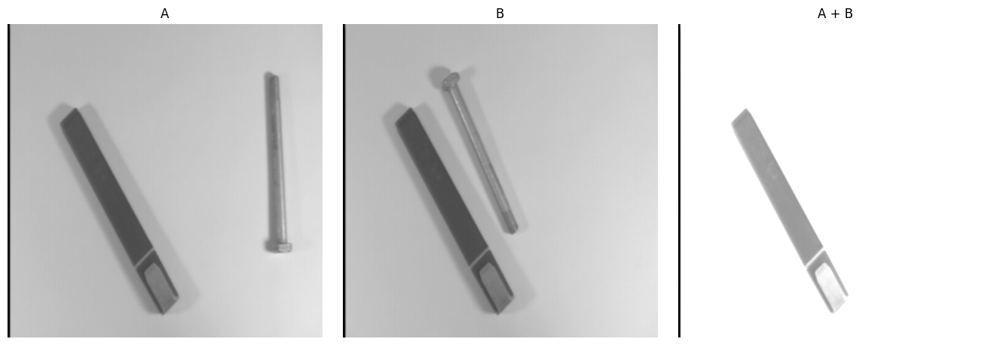

In [ ]:
A3 = np.array([[0, 100, 10], [4, 0, 10], [8, 0, 5]], np.uint8)
B3 = np.array([[10, 100, 5], [2, 0, 0], [0, 10, 10]], np.uint8)
print('A + B =\n', cv2.add(A3, B3))

add_img = cv2.add(A, B)
show([A, B, add_img], ['A', 'B', 'A + B'], cols=3)

#03_2. Subtraction

A - B =
 [[ 0  0  5]
 [ 2  0 10]
 [ 8  0  0]]


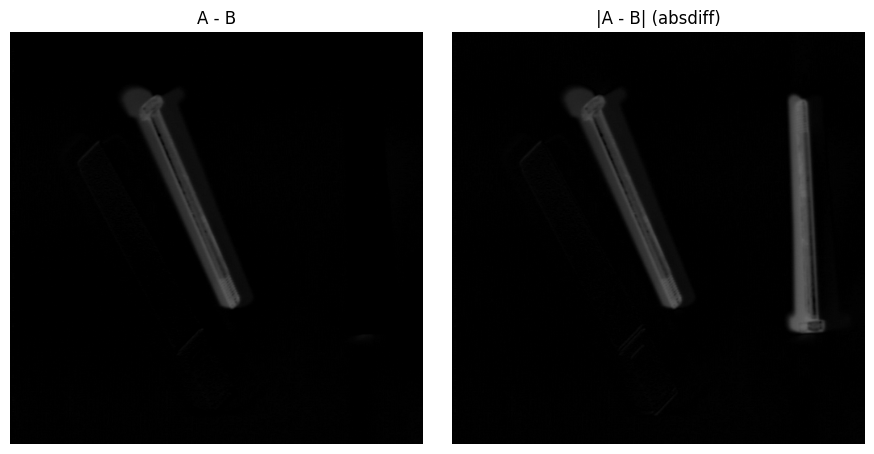

In [ ]:
print('A - B =\n', cv2.subtract(A3, B3))

sub_img  = cv2.subtract(A, B)
diff_img = cv2.absdiff(A, B)

show([sub_img, diff_img], ['A - B', '|A - B| (absdiff)'], cols=2)

#03_3. Multiplication

A x B =
 [[  0 255  50]
 [  8   0   0]
 [  0   0  50]]


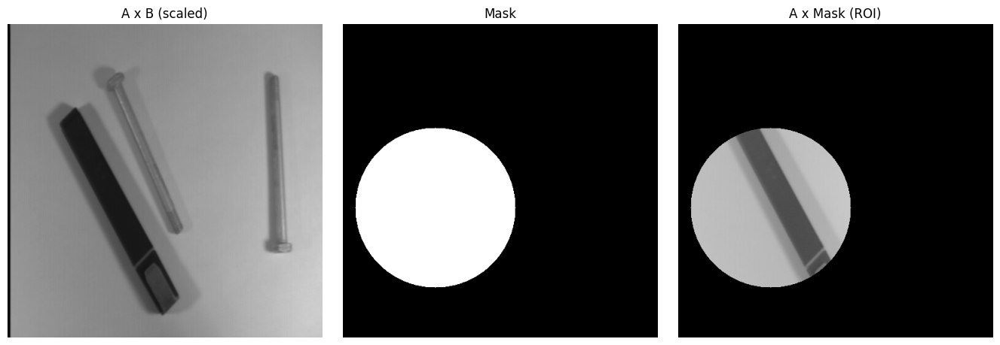

In [ ]:
print('A x B =\n', cv2.multiply(A3, B3))

mul_img = cv2.multiply(A, B, scale=1 / 255)

mask = np.zeros_like(A)
cv2.circle(mask, (150, 300), 130, 1, -1)
roi = cv2.multiply(A, mask)

show([mul_img, mask * 255, roi], ['A x B (scaled)', 'Mask', 'A x Mask (ROI)'], cols=3)

#03_4. Division

A / B =
 [[0 1 2]
 [2 0 0]
 [0 0 0]]


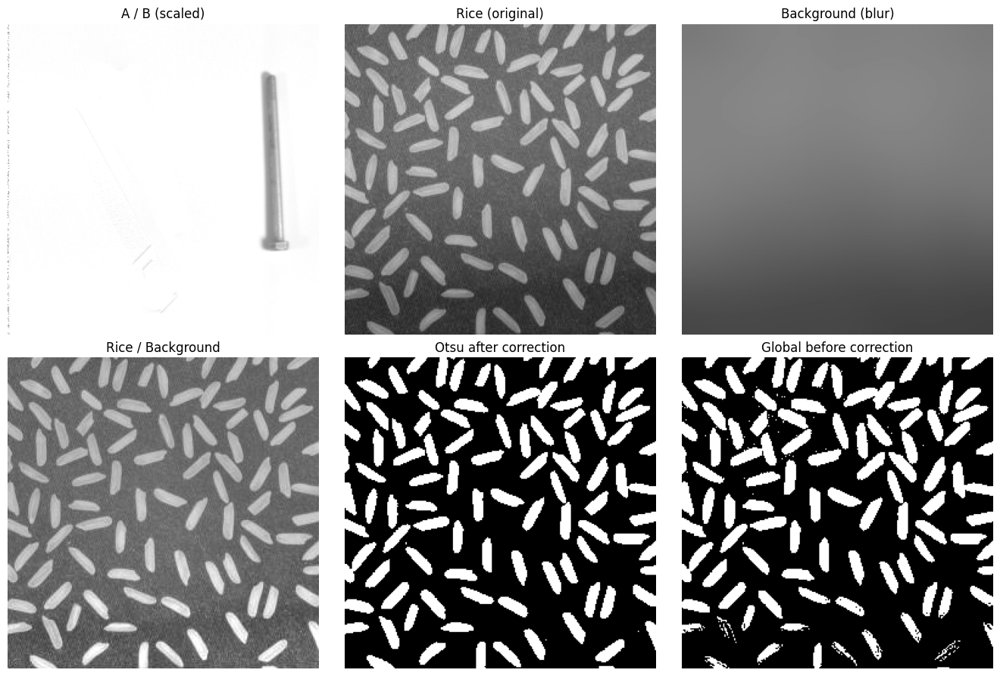

In [ ]:
print('A / B =\n', cv2.divide(A3, B3))

div_img = cv2.divide(A, B, scale=255)

background = cv2.GaussianBlur(rice, (0, 0), 25)
corrected  = cv2.divide(rice, background, scale=128)
_, th_corrected = cv2.threshold(corrected, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show([div_img, rice, background, corrected, th_corrected, th_global],
     ['A / B (scaled)', 'Rice (original)', 'Background (blur)', 'Rice / Background',
      'Otsu after correction', 'Global before correction'], cols=3)

#04_1. AND Operation

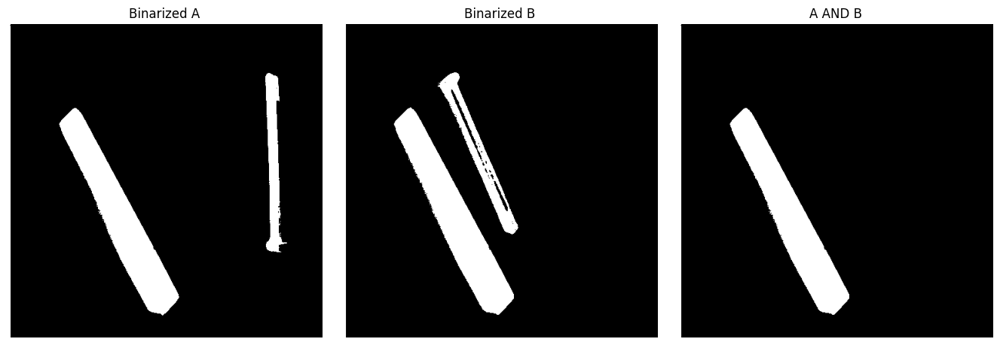

In [ ]:
_, bin_a = cv2.threshold(A, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
_, bin_b = cv2.threshold(B, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

op_and = cv2.bitwise_and(bin_a, bin_b)   # intersection

show([bin_a, bin_b, op_and], ['Binarized A', 'Binarized B', 'A AND B'], cols=3)

#04_2. OR Operation

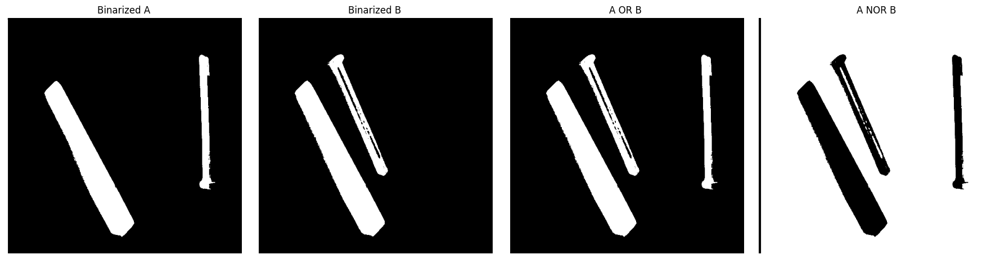

In [ ]:
op_or  = cv2.bitwise_or(bin_a, bin_b)    # union
op_nor = cv2.bitwise_not(op_or)          # NOR = NOT(OR)

show([bin_a, bin_b, op_or, op_nor], ['Binarized A', 'Binarized B', 'A OR B', 'A NOR B'], cols=4)

#04_3. NOT Operation

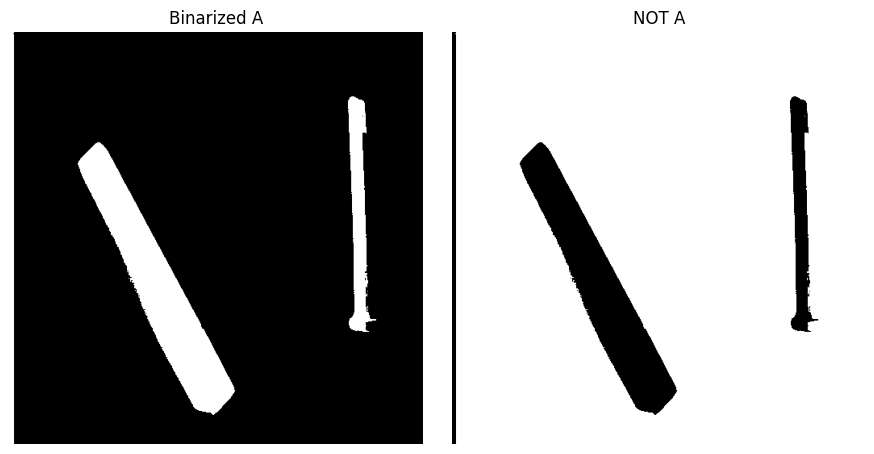

A   B   AND  OR  NOT A  NOR 
----------------------------
0   0   0    0   1      1   
0   1   0    1   1      0   
1   0   0    1   0      0   
1   1   1    1   0      0   


In [ ]:
op_not = cv2.bitwise_not(bin_a)          # 1 <-> 0

show([bin_a, op_not], ['Binarized A', 'NOT A'], cols=2)

a = np.array([0, 0, 1, 1], np.uint8)
b = np.array([0, 1, 0, 1], np.uint8)
print(f'{"A":<4}{"B":<4}{"AND":<5}{"OR":<4}{"NOT A":<7}{"NOR":<4}')
print('-' * 28)
for i in range(4):
    print(f'{a[i]:<4}{b[i]:<4}{(a & b)[i]:<5}{(a | b)[i]:<4}{(1 - a)[i]:<7}{(1 - (a | b))[i]:<4}')

#05_1. Structuring Element

In [ ]:
# Rules : 4 structuring element, padding for printing same_size
SES = [
    ('Vertical 3x1',    np.ones((3, 1), np.uint8),                          'Top 1, Bottom 1'),
    ('Horizontal 1x3',  np.ones((1, 3), np.uint8),                          'Left 1, Right 1'),
    ('Square 3x3',      np.ones((3, 3), np.uint8),                          'All four sides, 1'),
    ('Circle/disk 3x3', cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3)), 'All four sides, 1'),
]

for name, se, pad in SES:
    print(f'[{name}]  padding : {pad}\n{se}\n')

se_rect = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))   # 05_4 opening/closing

[Vertical 3x1]  padding : Top 1, Bottom 1
[[1]
 [1]
 [1]]

[Horizontal 1x3]  padding : Left 1, Right 1
[[1 1 1]]

[Square 3x3]  padding : All four sides, 1
[[1 1 1]
 [1 1 1]
 [1 1 1]]

[Circle/disk 3x3]  padding : All four sides, 1
[[0 1 0]
 [1 1 1]
 [0 1 0]]



#05_2. Dilation - structuring elements & padding

| Structuring element | Example | Padding for same-size output |
|---|---|---|
| Vertical $3 \times 1$ | $[1, 1, 1]^T$ | Top 1, Bottom 1 |
| Horizontal $1 \times 3$ | $[1, 1, 1]$ | Left 1, Right 1 |
| Square $3 \times 3$ | All ones | All four sides, 1 |
| Circle/disk $3 \times 3$ | Cross-like | All four sides, 1 |

In [ ]:
# 7x7 example
toy = np.zeros((7, 7), np.uint8)
toy[3, 3], toy[1, 5], toy[5, 1] = 1, 1, 1
print('input (7x7)\n', toy, '\n')

for name, se, pad in SES:
    out = cv2.dilate(toy, se)
    print(f'[{name}]  padding : {pad}  {toy.shape} -> {out.shape}\n{out}\n')

input (7x7)
 [[0 0 0 0 0 0 0]
 [0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 0 0 0 0]
 [0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0]] 

[Vertical 3x1]  padding : Top 1, Bottom 1  (7, 7) -> (7, 7)
[[0 0 0 0 0 1 0]
 [0 0 0 0 0 1 0]
 [0 0 0 1 0 1 0]
 [0 0 0 1 0 0 0]
 [0 1 0 1 0 0 0]
 [0 1 0 0 0 0 0]
 [0 1 0 0 0 0 0]]

[Horizontal 1x3]  padding : Left 1, Right 1  (7, 7) -> (7, 7)
[[0 0 0 0 0 0 0]
 [0 0 0 0 1 1 1]
 [0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]
 [1 1 1 0 0 0 0]
 [0 0 0 0 0 0 0]]

[Square 3x3]  padding : All four sides, 1  (7, 7) -> (7, 7)
[[0 0 0 0 1 1 1]
 [0 0 0 0 1 1 1]
 [0 0 1 1 1 1 1]
 [0 0 1 1 1 0 0]
 [1 1 1 1 1 0 0]
 [1 1 1 0 0 0 0]
 [1 1 1 0 0 0 0]]

[Circle/disk 3x3]  padding : All four sides, 1  (7, 7) -> (7, 7)
[[0 0 0 0 0 1 0]
 [0 0 0 0 1 1 1]
 [0 0 0 1 0 1 0]
 [0 0 1 1 1 0 0]
 [0 1 0 1 0 0 0]
 [1 1 1 0 0 0 0]
 [0 1 0 0 0 0 0]]



#05_3. Dilation with 4 structuring elements

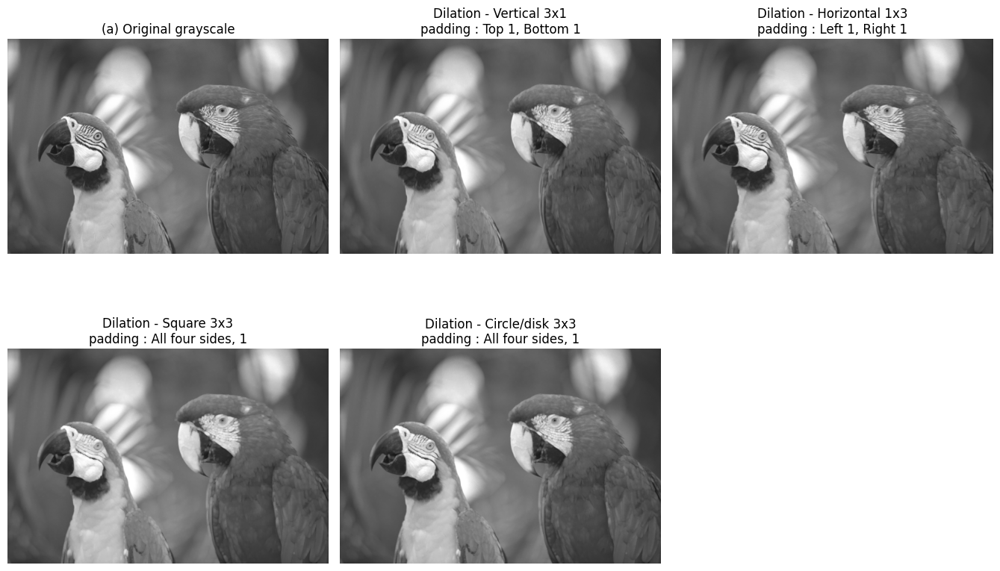

Structuring element padding             in -> out                   mean     delta mean
---------------------------------------------------------------------------------------
Original            -                   (428, 640)                  109.13   -         
Vertical 3x1        Top 1, Bottom 1     (428, 640) -> (428, 640)    111.68   2.55      
Horizontal 1x3      Left 1, Right 1     (428, 640) -> (428, 640)    112.04   2.91      
Square 3x3          All four sides, 1   (428, 640) -> (428, 640)    114.41   5.28      
Circle/disk 3x3     All four sides, 1   (428, 640) -> (428, 640)    113.03   3.90      


In [ ]:
img = cv2.resize(parrot, None, fx=0.42, fy=0.42, interpolation=cv2.INTER_AREA)   # 1524x1018 -> 640x428
dil = [cv2.dilate(img, se) for _, se, _ in SES]

show([img] + dil, ['(a) Original grayscale'] + [f'Dilation - {n}\npadding : {p}' for n, _, p in SES], cols=3)

print(f'{"Structuring element":<20}{"padding":<20}{"in -> out":<28}{"mean":<9}{"delta mean":<10}')
print('-' * 87)
print(f'{"Original":<20}{"-":<20}{str(img.shape):<28}{img.mean():<9.2f}{"-":<10}')
for (name, se, pad), d in zip(SES, dil):
    print(f'{name:<20}{pad:<20}{f"{img.shape} -> {d.shape}":<28}{d.mean():<9.2f}{d.mean() - img.mean():<10.2f}')

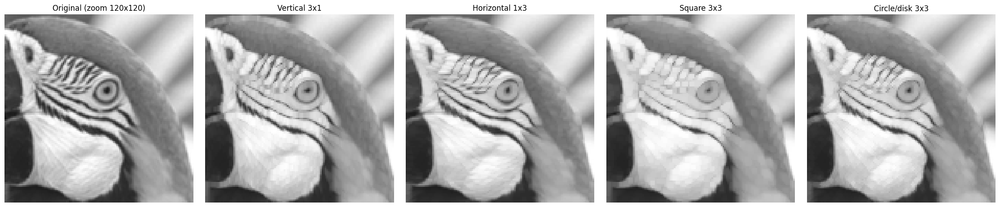

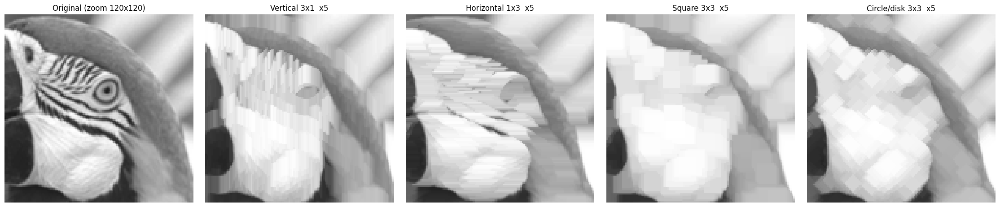

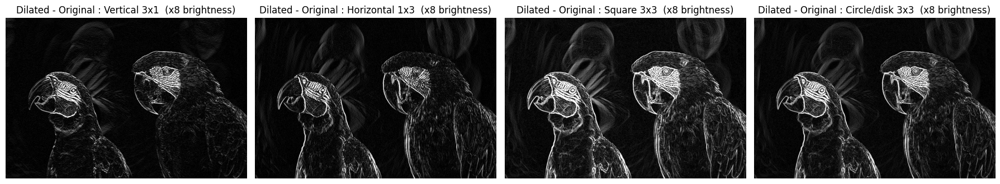

In [ ]:
# Compare by zooming in
y, x, SZ = 145, 115, 120
show([img[y:y + SZ, x:x + SZ]] + [d[y:y + SZ, x:x + SZ] for d in dil],
     [f'Original (zoom {SZ}x{SZ})'] + [n for n, _, _ in SES], cols=5)

# applied the same structuring element 5 times to create a comparison.
show([img[y:y + SZ, x:x + SZ]] + [cv2.dilate(img, se, iterations=5)[y:y + SZ, x:x + SZ] for _, se, _ in SES],
     [f'Original (zoom {SZ}x{SZ})'] + [f'{n}  x5' for n, _, _ in SES], cols=5)

# dilated - original and boosted brightness to clear the effect
show([cv2.multiply(cv2.subtract(d, img), 8) for d in dil],
     [f'Dilated - Original : {n}  (x8 brightness)' for n, _, _ in SES], cols=4)

#05_4. Dilation on a text image


text image : (434, 615) | range : 15 ~ 227  -> 어두운 배경 + 밝은 글자


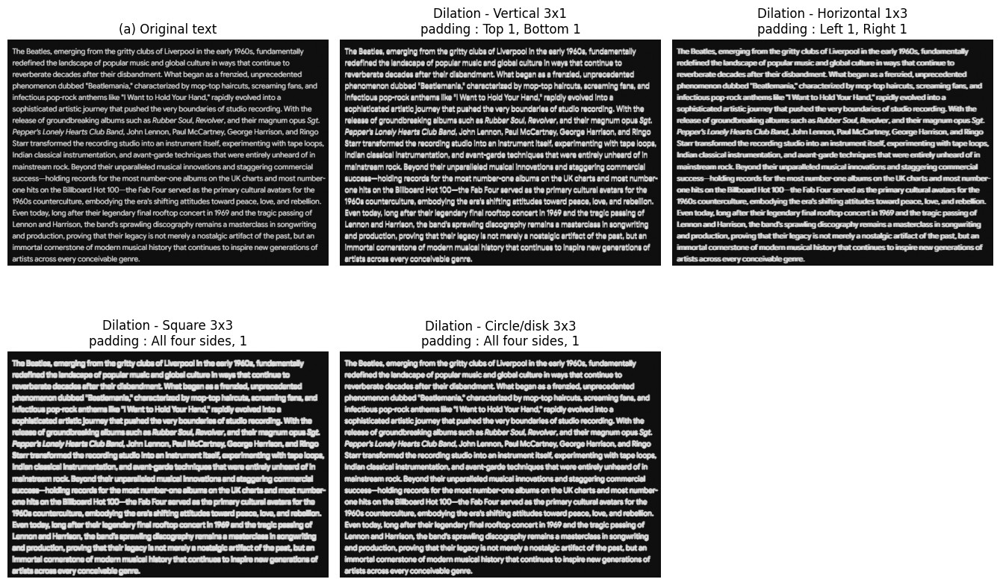

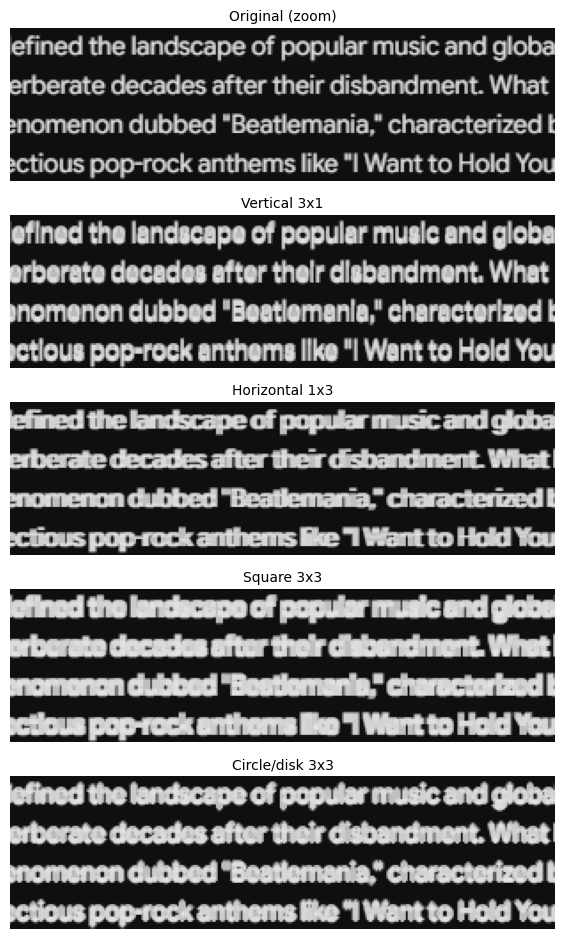

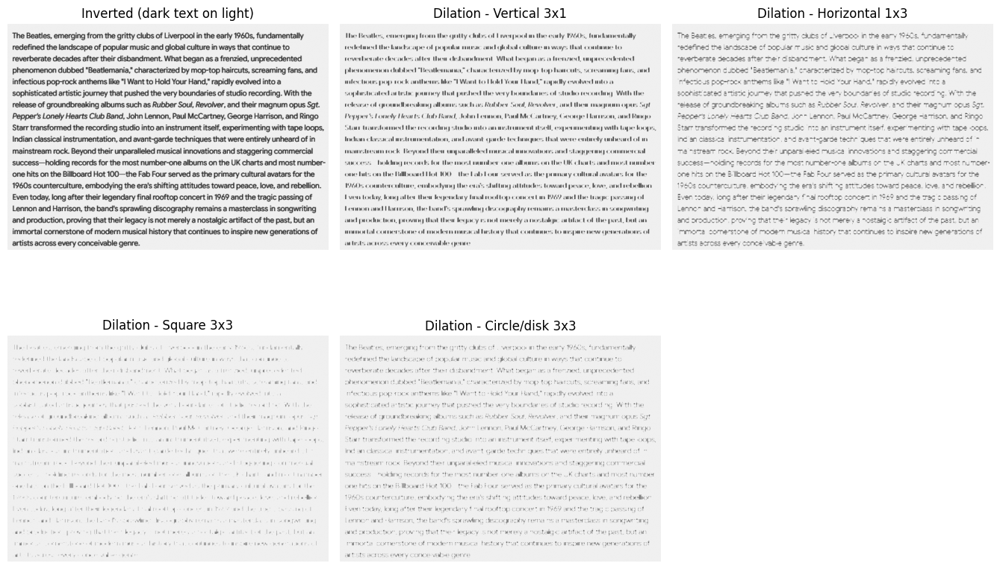


Structuring element bright pixels         change    
----------------------------------------------------
Vertical 3x1        43339 -> 68716        +58.6%
Horizontal 1x3      43339 -> 73617        +69.9%
Square 3x3          43339 -> 98972        +128.4%
Circle/disk 3x3     43339 -> 87313        +101.5%


In [ ]:
text = cv2.imread(f'{BASE}/02_morphology/beatles.png', cv2.IMREAD_GRAYSCALE)
assert text is not None, '이미지를 찾을 수 없음 : 02_morphology/beatles.png'
print(f'text image : {text.shape} | range : {text.min()} ~ {text.max()}  -> 어두운 배경 + 밝은 글자')

dil_t = [cv2.dilate(text, se) for _, se, _ in SES]
show([text] + dil_t, ['(a) Original text'] + [f'Dilation - {n}\npadding : {p}' for n, _, p in SES], cols=3)

# Since the strokes are thin, enlarge only a few lines for a vertical comparison
h, w = text.shape
ty, tx, TH, TW = h // 12, w // 20, h // 5, w // 2
crops  = [text[ty:ty + TH, tx:tx + TW]] + [d[ty:ty + TH, tx:tx + TW] for d in dil_t]
titles = ['Original (zoom)'] + [n for n, _, _ in SES]

plt.figure(figsize=(9, 1.9 * len(crops)))
for i, (im, t) in enumerate(zip(crops, titles), 1):
    plt.subplot(len(crops), 1, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=10); plt.axis('off')
plt.tight_layout(); plt.show()

# Note: If the text is black and the background is white,
# the background scales in the opposite direction, making the text thinner
inv = 255 - text
show([inv] + [cv2.dilate(inv, se) for _, se, _ in SES],
     ['Inverted (dark text on light)'] + [f'Dilation - {n}' for n, _, _ in SES], cols=3)

n0 = np.count_nonzero(text > 128)
print(f'\n{"Structuring element":<20}{"bright pixels":<22}{"change":<10}')
print('-' * 52)
for (name, se, _), d in zip(SES, dil_t):
    n1 = np.count_nonzero(d > 128)
    print(f'{name:<20}{f"{n0} -> {n1}":<22}{100 * n1 / n0 - 100:+.1f}%')

#06_1. Erosion with 4 structuring elements

In [ ]:
# 7x7 example : erosion shrinks a region, so start from a filled block + an isolated dot
toy_e = np.zeros((7, 7), np.uint8)
toy_e[1:6, 1:6], toy_e[0, 0] = 1, 1
print('input (7x7)\n', toy_e, '\n')

for name, se, pad in SES:
    out = cv2.erode(toy_e, se)
    print(f'[{name}]  padding : {pad}  {toy_e.shape} -> {out.shape}\n{out}\n')

input (7x7)
 [[1 0 0 0 0 0 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 0 0 0 0 0 0]] 

[Vertical 3x1]  padding : Top 1, Bottom 1  (7, 7) -> (7, 7)
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]

[Horizontal 1x3]  padding : Left 1, Right 1  (7, 7) -> (7, 7)
[[0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]]

[Square 3x3]  padding : All four sides, 1  (7, 7) -> (7, 7)
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]

[Circle/disk 3x3]  padding : All four sides, 1  (7, 7) -> (7, 7)
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]



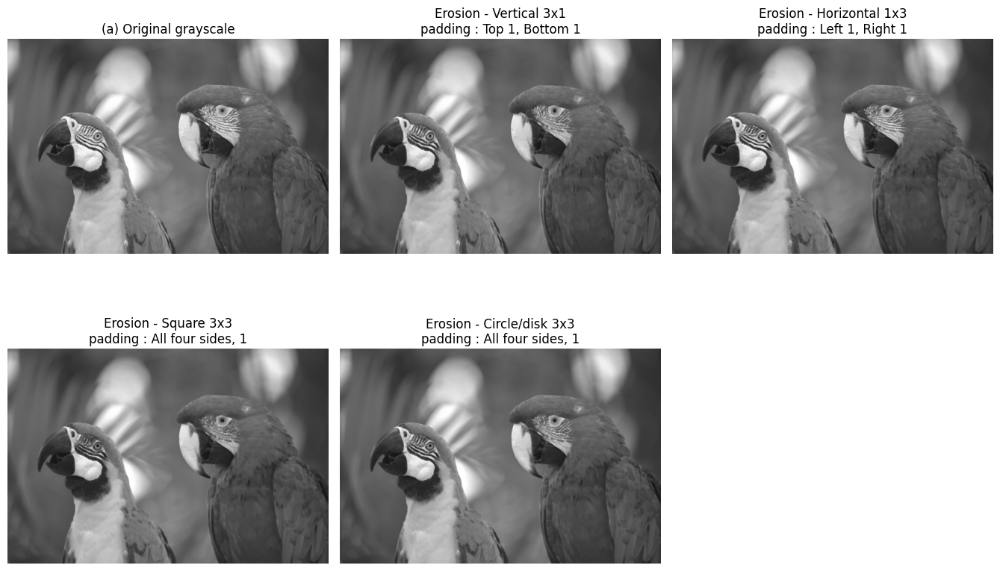

Structuring element padding             in -> out                   mean     delta mean
---------------------------------------------------------------------------------------
Original            -                   (428, 640)                  109.13   -         
Vertical 3x1        Top 1, Bottom 1     (428, 640) -> (428, 640)    106.58   -2.55     
Horizontal 1x3      Left 1, Right 1     (428, 640) -> (428, 640)    106.22   -2.91     
Square 3x3          All four sides, 1   (428, 640) -> (428, 640)    103.87   -5.26     
Circle/disk 3x3     All four sides, 1   (428, 640) -> (428, 640)    105.24   -3.89     


In [ ]:
ero = [cv2.erode(img, se) for _, se, _ in SES]   # same image as 05_3 (parrots_gray, 0.42x)

show([img] + ero, ['(a) Original grayscale'] + [f'Erosion - {n}\npadding : {p}' for n, _, p in SES], cols=3)

print(f'{"Structuring element":<20}{"padding":<20}{"in -> out":<28}{"mean":<9}{"delta mean":<10}')
print('-' * 87)
print(f'{"Original":<20}{"-":<20}{str(img.shape):<28}{img.mean():<9.2f}{"-":<10}')
for (name, se, pad), e in zip(SES, ero):
    print(f'{name:<20}{pad:<20}{f"{img.shape} -> {e.shape}":<28}{e.mean():<9.2f}{e.mean() - img.mean():<10.2f}')

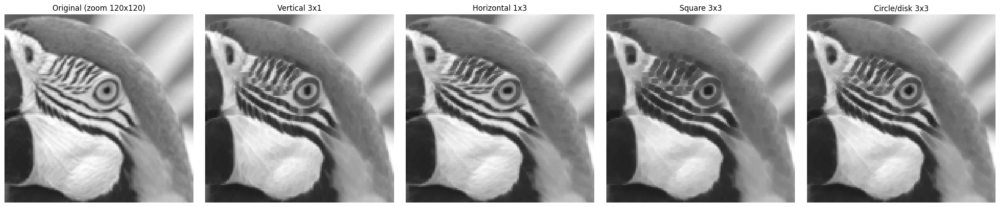

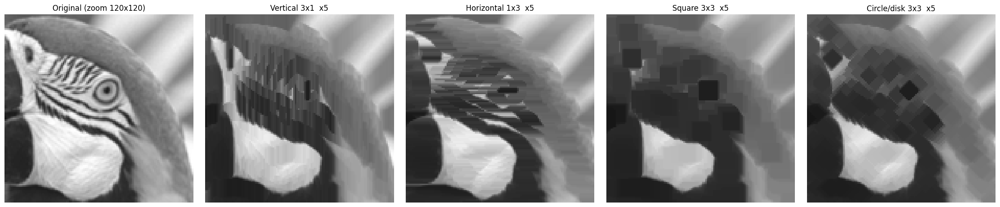

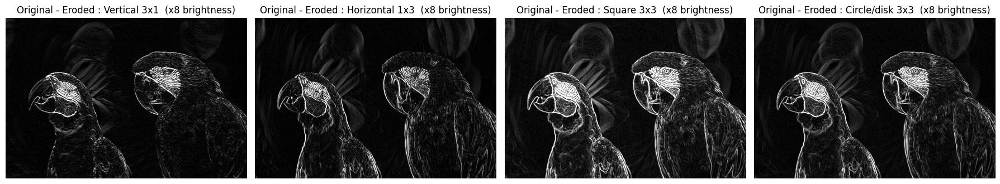

In [ ]:
# Compare by zooming in (same crop as 05_3)
y, x, SZ = 145, 115, 120
show([img[y:y + SZ, x:x + SZ]] + [e[y:y + SZ, x:x + SZ] for e in ero],
     [f'Original (zoom {SZ}x{SZ})'] + [n for n, _, _ in SES], cols=5)

# applied the same structuring element 5 times to create a comparison.
show([img[y:y + SZ, x:x + SZ]] + [cv2.erode(img, se, iterations=5)[y:y + SZ, x:x + SZ] for _, se, _ in SES],
     [f'Original (zoom {SZ}x{SZ})'] + [f'{n}  x5' for n, _, _ in SES], cols=5)

# original - eroded and boosted brightness to clear the effect
show([cv2.multiply(cv2.subtract(img, e), 8) for e in ero],
     [f'Original - Eroded : {n}  (x8 brightness)' for n, _, _ in SES], cols=4)

#06_2. Erosion on a text image

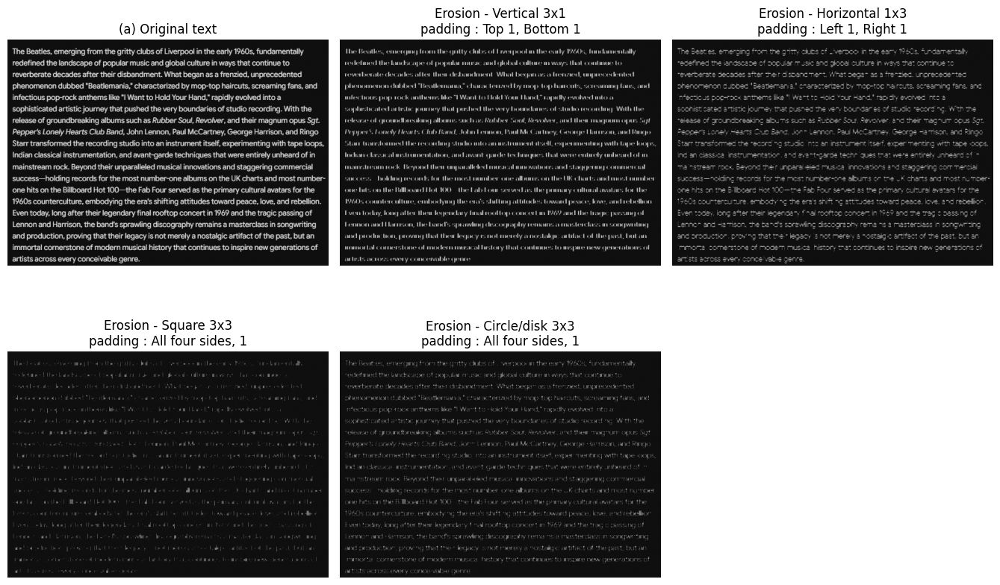

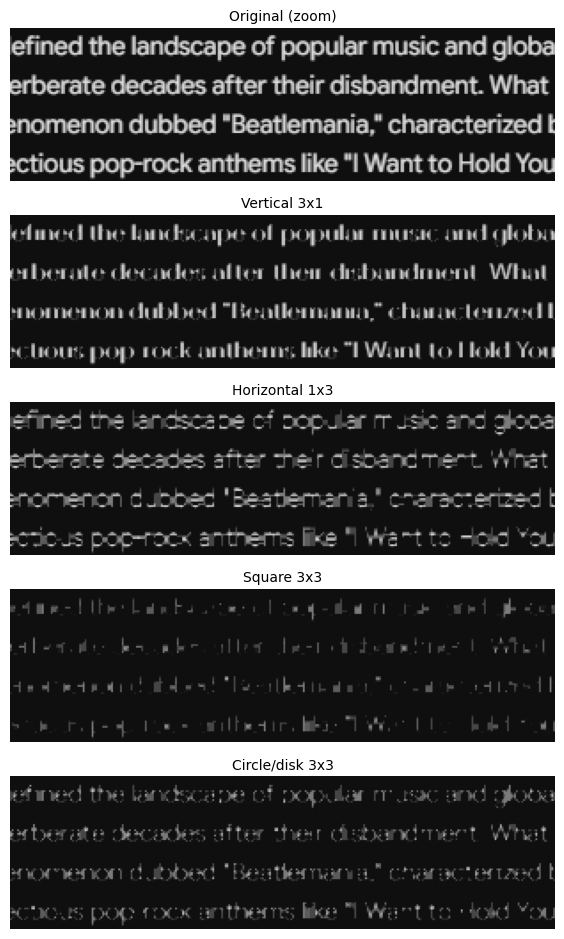

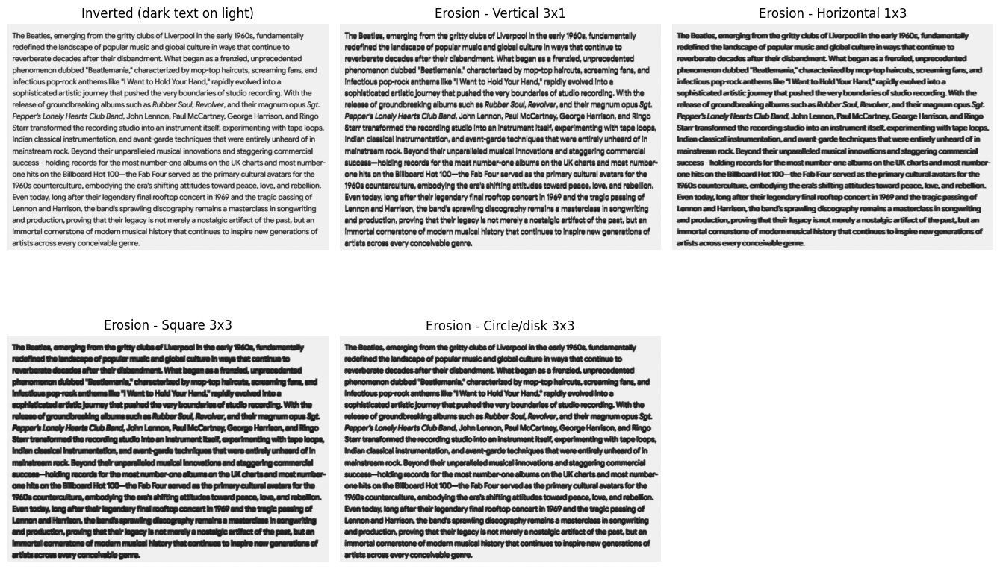


Structuring element bright pixels         change    
----------------------------------------------------
Vertical 3x1        43339 -> 19578        -54.8%
Horizontal 1x3      43339 -> 11958        -72.4%
Square 3x3          43339 -> 87           -99.8%
Circle/disk 3x3     43339 -> 2438         -94.4%


In [ ]:
ero_t = [cv2.erode(text, se) for _, se, _ in SES]   # same image as 05_4 (beatles.png)
show([text] + ero_t, ['(a) Original text'] + [f'Erosion - {n}\npadding : {p}' for n, _, p in SES], cols=3)

# Since the strokes are thin, enlarge only a few lines for a vertical comparison
crops  = [text[ty:ty + TH, tx:tx + TW]] + [e[ty:ty + TH, tx:tx + TW] for e in ero_t]
titles = ['Original (zoom)'] + [n for n, _, _ in SES]

plt.figure(figsize=(9, 1.9 * len(crops)))
for i, (im, t) in enumerate(zip(crops, titles), 1):
    plt.subplot(len(crops), 1, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=10); plt.axis('off')
plt.tight_layout(); plt.show()

# Note: If the text is black and the background is white,
# the background shrinks instead, making the text thicker (opposite of dilation)
show([inv] + [cv2.erode(inv, se) for _, se, _ in SES],
     ['Inverted (dark text on light)'] + [f'Erosion - {n}' for n, _, _ in SES], cols=3)

print(f'\n{"Structuring element":<20}{"bright pixels":<22}{"change":<10}')
print('-' * 52)
for (name, se, _), e in zip(SES, ero_t):
    n1 = np.count_nonzero(e > 128)
    print(f'{name:<20}{f"{n0} -> {n1}":<22}{100 * n1 / n0 - 100:+.1f}%')